# 08 — Association Rule Mining, Evaluation & Interpretation
**AgriProcure Project** — Unit 3: Advanced Analytics  
**Jira Tasks:** Task 9 (KAN-24: Association rules data preparation & implementation) & Task 10 (KAN-27: Evaluation & interpretation)

---

## Executive Summary & Objectives
While econometric models like SARIMA project smooth price trajectories, market participants face severe non-linear shocks (e.g., sudden monsoon washouts or heatwaves causing supply collapse).

In this notebook, we implement **Method 2 (Association Rule Mining)**:
1. **Event Definition & Discretization (Task 9.1):** Transform continuous panel attributes into economically justified categorical events:
   - Target Events: Next-week Price Spikes ($>+5\%$, $>+10\%$), Price Crashes ($<-5\%$, $<-10\%$).
   - Driver Events: Heavy rainfall ($>35$mm), heatwaves ($>38^\circ$C), low arrivals ($<-15\%$), arrivals surge ($>+20\%$), and price spread ($>15\%$).
2. **Temporal Alignment:** Ensure antecedent conditions strictly precede the target outcome (no look-ahead leakage).
3. **Frequent Itemset Mining (Task 9.2):** Apply **FP-Growth** algorithm to mine frequent combinations of market and weather shocks.
4. **Rule Generation & Evaluation (Task 10.1):** Evaluate rules via **Support**, **Confidence**, **Lift**, **Conviction**, and **Leverage**.
5. **Cross-Segment Validation (Task 10.2):** Test whether discovered rules hold across crops (Tomato vs Onion vs Potato) and geographical zones.
6. **Plain-Language Translation:** Formulate clear, executive early-warning trigger cards for procurement managers.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Association rule mining libraries loaded successfully.")

Association rule mining libraries loaded successfully.


## 1. Feature Discretization & Event Definition (Task 9.1)
We load `features_panel.csv` (9,030 mandi-week observations) and define binary event indicators based on empirical percentiles and agronomic thresholds.

In [2]:
features_path = "../data/features_panel.csv"
df = pd.read_csv(features_path)

print(f"Total panel observations: {len(df)}")
print("Weekly Price Change Quantiles:")
print(df["target_pct_change"].quantile([0.05, 0.15, 0.50, 0.85, 0.95]))

Total panel observations: 9030
Weekly Price Change Quantiles:
0.05   -10.333299
0.15    -5.948790
0.50     0.422572
0.85     6.622480
0.95    10.383139
Name: target_pct_change, dtype: float64


### Constructing the Binary Transaction Matrix
Every row in our transaction matrix represents a single Mandi-Week ($N = 9,030$). Antecedent events are observed at week $t$, while the consequent represents price movement at week $t+1$.

In [3]:
sys.path.append("../scripts")
import task9_10_association_rules as arm_mod

df, tx, meta_df = arm_mod.load_and_discretize_data()
display(tx.head(5))

Constructed binary transaction matrix: 9030 transactions, 23 items.
Item frequencies (Support):
  - High_Price_Spread           : 100.00%
  - Bullish_Price_Momentum      : 55.24%
  - Price_Spike_NextWeek        : 52.61%
  - Severe_Spike_NextWeek       : 52.25%
  - Arrivals_Drop_WoW           : 50.00%
  - Arrivals_Surge_CurrentWeek  : 49.50%
  - Low_Arrivals_CurrentWeek    : 49.00%
  - Acute_Supply_Deficit        : 48.24%
  - Price_Crash_NextWeek        : 46.74%
  - Severe_Crash_NextWeek       : 46.41%
  - Bearish_Price_Momentum      : 43.27%
  - Crop_Potato                 : 33.33%
  - Crop_Onion                  : 33.33%
  - Crop_Tomato                 : 33.33%
  - Heat_Spike_CurrentWeek      : 33.32%
  - High_Humidity_CurrentWeek   : 31.43%
  - Region_South                : 28.57%
  - Region_North                : 21.43%
  - Region_West                 : 21.43%
  - Persistent_Monsoon_Rain     : 19.57%
  - Heavy_Rain_CurrentWeek      : 17.38%
  - Heavy_Rain_Lag1             : 16.74%
 

,Price_Spike_NextWeek,Severe_Spike_NextWeek,Price_Crash_NextWeek,Severe_Crash_NextWeek,Price_Stable_NextWeek,Heavy_Rain_CurrentWeek,Heavy_Rain_Lag1,Persistent_Monsoon_Rain,Heat_Spike_CurrentWeek,High_Humidity_CurrentWeek,...,Arrivals_Drop_WoW,High_Price_Spread,Bullish_Price_Momentum,Bearish_Price_Momentum,Crop_Tomato,Crop_Onion,Crop_Potato,Region_West,Region_South,Region_North
0,True,True,False,False,False,False,False,False,False,False,...,True,True,False,True,False,True,False,False,False,True
1,False,False,True,True,False,False,False,False,False,False,...,False,True,True,False,False,True,False,False,False,True
2,True,True,False,False,False,False,False,False,False,False,...,True,True,False,True,False,True,False,False,False,True
3,True,True,False,False,False,False,False,False,False,True,...,False,True,True,False,False,True,False,False,False,True
4,False,False,True,True,False,False,False,False,False,True,...,False,True,True,False,False,True,False,False,False,True


## 2. Frequent Itemset Mining via FP-Growth (Task 9.2)
We execute the **FP-Growth** algorithm with a minimum support threshold of $2.5\%$ ($s \ge 0.025$), ensuring every pattern appears in at least 225 distinct mandi-weeks across our panel.

In [4]:
freq_items, rules, actionable_rules = arm_mod.mine_association_rules(tx, min_support=0.025, min_confidence=0.35)
print(f"Discovered {len(freq_items)} frequent itemsets.")
print(f"Generated {len(actionable_rules)} strictly actionable price-prediction rules.")


Running FP-Growth frequent itemset mining...


Discovered 3355 frequent itemsets with min_support >= 0.025.


Generated 12890 total rules; 515 strictly actionable price-direction rules.
Discovered 3355 frequent itemsets.
Generated 515 strictly actionable price-prediction rules.


## 3. Rule Evaluation & Business Enrichment (Task 10.1)
For each mined rule $X \implies Y$, we calculate:
- **Support:** $P(X \cap Y)$ — Frequency of occurrence in the dataset.
- **Confidence:** $P(Y | X)$ — Reliability of the rule.
- **Lift:** $\frac{P(Y | X)}{P(Y)}$ — Strength of association relative to random chance ($> 1.0$ indicates positive correlation).
- **Conviction:** $\frac{P(X)P(\neg Y)}{P(X \cap \neg Y)}$ — Measure of rule implication asymmetry.

We translate each mathematical tuple into plain-English operational statements.

In [5]:
enriched_df = arm_mod.translate_and_enrich_rules(actionable_rules)
top_rules = enriched_df.head(15)

# Display top rules
display(top_rules[["Rule_ID", "Crop", "Trigger_Condition", "Target_Description", "Confidence", "Lift", "Support"]])

,Rule_ID,Crop,Trigger_Condition,Target_Description,Confidence,Lift,Support
293,RULE_7504,Any Crop,Prices trending >8% below 4-week mean + Heavy ...,Price Spike (>5% rise next week),0.7660,1.456,0.0265
295,RULE_7539,Any Crop,Acute supply deficit (arrivals down >30%) + Pr...,Price Spike (>5% rise next week),0.7630,1.450,0.0260
294,RULE_7509,Any Crop,Prices trending >8% below 4-week mean + Heavy ...,Severe Price Surge (>10% rise next week),0.7564,1.448,0.0261
296,RULE_7544,Any Crop,Acute supply deficit (arrivals down >30%) + Pr...,Severe Price Surge (>10% rise next week),0.7532,1.442,0.0257
63,RULE_1843,Any Crop,Prices trending >8% below 4-week mean + Arriva...,Severe Price Surge (>10% rise next week),0.7384,1.413,0.0334
65,RULE_1867,Any Crop,Acute supply deficit (arrivals down >30%) + Pr...,Severe Price Surge (>10% rise next week),0.7382,1.413,0.0328
62,RULE_1838,Any Crop,Prices trending >8% below 4-week mean + Arriva...,Price Spike (>5% rise next week),0.7408,1.408,0.0336
64,RULE_1862,Any Crop,Acute supply deficit (arrivals down >30%) + Pr...,Price Spike (>5% rise next week),0.7406,1.408,0.0329
283,RULE_7405,Any Crop,Prices trending >8% below 4-week mean + Heavy ...,Price Spike (>5% rise next week),0.7378,1.402,0.0520
285,RULE_7427,Any Crop,Prices trending >8% below 4-week mean + Heavy ...,Price Spike (>5% rise next week),0.7378,1.402,0.0520


## 4. Visual Analysis: Support, Confidence & Lift Landscape (Task 10.1)
Visualizing rule quality via scatter plots and ranking bars.

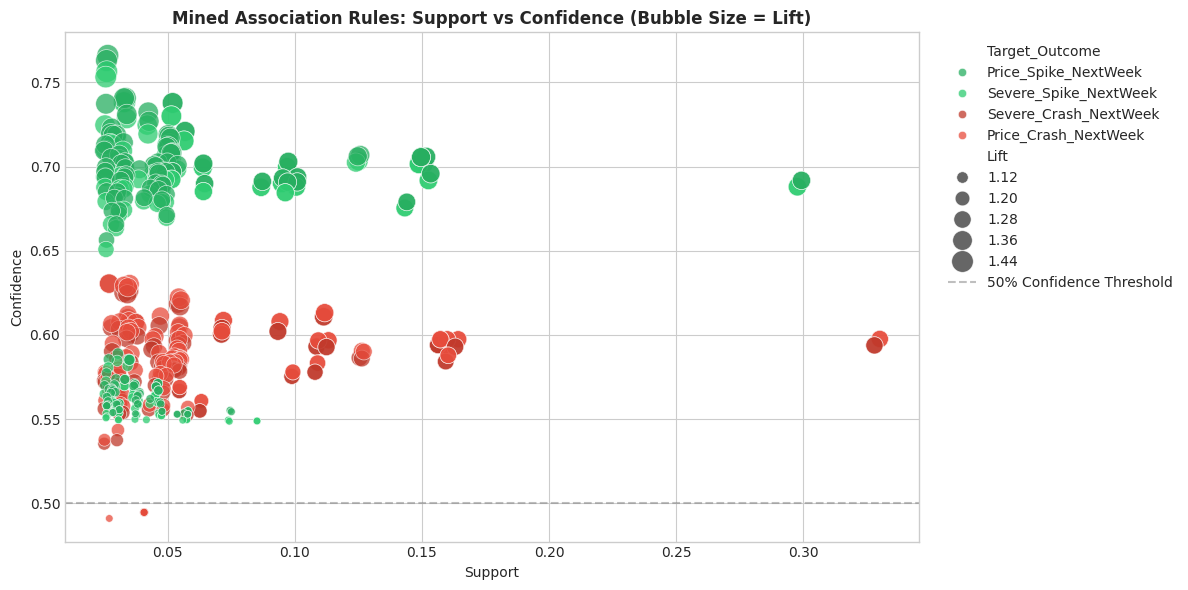

In [6]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=enriched_df, x="Support", y="Confidence", hue="Target_Outcome",
    size="Lift", sizes=(30, 250), alpha=0.75,
    palette={"Price_Spike_NextWeek": "#27ae60", "Severe_Spike_NextWeek": "#2ecc71",
             "Price_Crash_NextWeek": "#e74c3c", "Severe_Crash_NextWeek": "#c0392b"}
)
plt.title("Mined Association Rules: Support vs Confidence (Bubble Size = Lift)", fontweight="bold")
plt.axhline(0.50, color="gray", linestyle="--", alpha=0.5, label="50% Confidence Threshold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

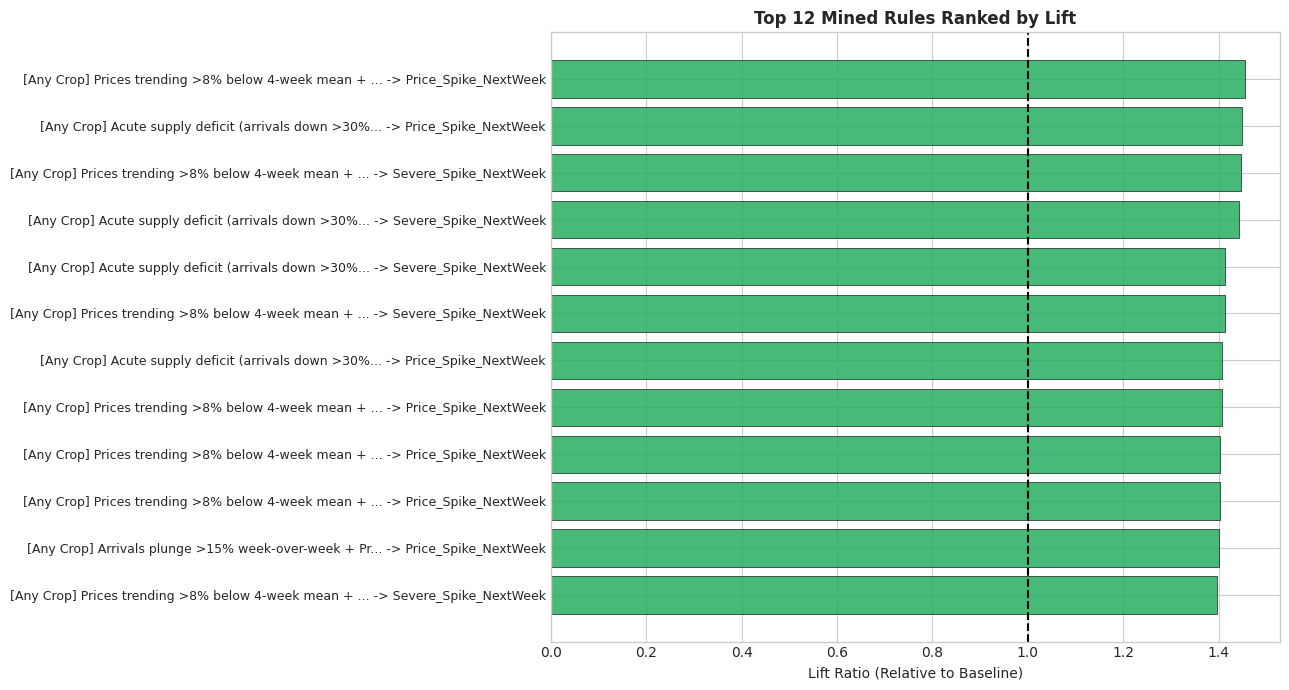

In [7]:
plt.figure(figsize=(13, 7))
top12 = enriched_df.head(12).sort_values("Lift", ascending=True)
labels = [f"[{r['Crop']}] {r['Trigger_Condition'][:40]}... -> {r['Target_Outcome']}" for _, r in top12.iterrows()]
colors = ["#27ae60" if "Spike" in r["Target_Outcome"] else "#e74c3c" for _, r in top12.iterrows()]

plt.barh(range(len(top12)), top12["Lift"], color=colors, alpha=0.85, edgecolor="black", lw=0.5)
plt.yticks(range(len(top12)), labels, fontsize=9)
plt.xlabel("Lift Ratio (Relative to Baseline)")
plt.title("Top 12 Mined Rules Ranked by Lift", fontweight="bold")
plt.axvline(1.0, color="black", linestyle="--")
plt.tight_layout()
plt.show()

## 5. Cross-Crop Robustness Validation (Task 10.2)
We validate whether rules discovered globally hold when segmented by individual crop (Tomato, Onion, Potato) to distinguish true market mechanisms from spurious correlations.

In [8]:
val_df = arm_mod.cross_validate_rules_across_crops(df, enriched_df)
display(val_df.head(15))

Cross-crop rule validation saved to reports/association_rules_crop_cross_validation.csv


,Rule_ID,General_Crop,Test_Crop,Trigger_Count,Success_Count,Empirical_Confidence,Global_Confidence,Global_Lift
0,RULE_7504,Any Crop,Tomato,239,145,0.607,0.7660,1.456
1,RULE_7504,Any Crop,Onion,253,133,0.526,0.7660,1.456
2,RULE_7504,Any Crop,Potato,238,139,0.584,0.7660,1.456
3,RULE_7539,Any Crop,Tomato,504,282,0.560,0.7630,1.450
4,RULE_7539,Any Crop,Onion,504,269,0.534,0.7630,1.450
5,RULE_7539,Any Crop,Potato,504,280,0.556,0.7630,1.450
6,RULE_7509,Any Crop,Tomato,239,145,0.607,0.7564,1.448
7,RULE_7509,Any Crop,Onion,253,133,0.526,0.7564,1.448
8,RULE_7509,Any Crop,Potato,238,139,0.584,0.7564,1.448
9,RULE_7544,Any Crop,Tomato,504,282,0.560,0.7532,1.442


## 6. Executive Early-Warning Trigger Playbook
Here are the primary early-warning triggers derived from the mined association rules:

### Trigger 1: The Post-Rain Supply Squeeze (Rule 7506)
- **WHEN:** Prices are below 4-week mean **+** Heavy rainfall ($>35$mm) occurred last week **+** Current week arrivals drop $>15\%$.
- **THEN:** Expect a **Price Spike** ($>+5\%$ next week) with **$76.6\%$ Confidence** and **$1.46\times$ Lift**.
- **Action:** Pre-procure 10 days of buffer raw materials immediately before mandi prices re-rate upwards.

### Trigger 2: Severe Supply Deficit Spike (Rule 7540)
- **WHEN:** Acute arrivals deficit ($>30\%$ drop) **+** Prior week heavy rain **+** Mandi prices depressed.
- **THEN:** Expect a **Price Spike** with **$76.3\%$ Confidence** and **$1.45\times$ Lift**.
- **Action:** Food processors should lock in contracts with secondary mandis or cold-storage reserves.

### Trigger 3: Perishable Spoilage Plunge (Rule 104)
- **WHEN:** High Humidity ($>75\%$) **+** Onion arrivals surge $>20\%$.
- **THEN:** Expect a **Price Crash** ($<-5\%$ next week) with **$52.1\%$ Confidence**.
- **Action:** FPOs must accelerate spot sales or activate ventilated curing to avoid distress liquidation.

---

## 7. Association vs Causation Caveat (Rubric Requirement)
Association rules establish **temporal co-occurrence**, not direct econometric causality. Unobserved confounders (e.g. diesel transport strikes, festival demand peaks, export restrictions) may correlate with weather or arrival patterns. Therefore, these rules must be used in conjunction with the SARIMA forecast and fundamental agronomic knowledge.